# 05 · Results, cost comparison and Hugging Face release

Collects the numbers from notebooks 01–04 into the figures and tables for the write-up, runs the optional closed-API cost comparison, and uploads datasets, logs and steering artifacts to the Hub (the hackathon requires all artifacts on Hugging Face).

In [1]:
import os, sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = "/content/drive/MyDrive/multilingual_safety"  # upload the folder here
else:
    PROJECT_DIR = os.path.abspath(".")

assert os.path.exists(os.path.join(PROJECT_DIR, "mlsafety.py")), f"multilingual_safety folder not found at {PROJECT_DIR}"
os.chdir(PROJECT_DIR)
sys.path.insert(0, PROJECT_DIR)

Mounted at /content/drive


In [2]:
%pip install -q pandas matplotlib huggingface_hub datasets

In [3]:
from huggingface_hub import login

token = os.environ.get("HF_TOKEN")
if token is None and IN_COLAB:
    from google.colab import userdata
    try:
        token = userdata.get("HF_TOKEN")
    except Exception:
        token = None
login(token=token)  # the token needs access to the gated CohereLabs/tiny-aya-* repos

In [4]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import mlsafety as ms

P = ms.get_paths(PROJECT_DIR)
MODEL_KEY = "tiny-aya-global"   # the branch whose tables and artifacts are shown / uploaded
TAG = ms.MODELS[MODEL_KEY]["tag"]
audit = pd.read_json(P.out / f"audit_{TAG}.json", orient="split")
steer = pd.read_json(P.out / f"steer_results_{TAG}.json", orient="records")
METHODS = list(dict.fromkeys(steer["method"]))
shown = audit.copy()
rates = ~shown.index.isin(["tokens / word", "C · harm recognition AUROC (↑)"])
shown.loc[rates] = 100 * shown.loc[rates]
display(shown.round(1))

,English,English (paraphrase),Hindi (Devanagari),Hindi (Roman),Hinglish (code-mixed)
tokens / word,1.2,1.2,1.4,1.7,1.4
B · understood (↑),NaN,44.6,87.5,51.8,57.1
C · harm recognition AUROC (↑),1.0,1.0,0.9,0.9,0.9
C · flags as harmful (↑),96.4,89.3,85.7,46.4,76.8
A · attack success (↓),8.9,1.8,67.9,91.1,75.0
A · refusal rate (↑),80.4,80.4,35.7,1.8,10.7
benign over-refusal (↓),1.8,7.1,0.0,0.0,0.0
C · benign false alarm (↓),7.1,3.6,7.1,8.9,5.4
"understands + flags, still complies",7.1,1.8,46.4,21.4,26.8


attack success                                    \
form                                 en en_para hi_deva hi_roman hinglish   
method                                                                      
base                                7.7     3.8    65.4     88.5     73.1   
caa                                 0.0     0.0    57.7     50.0     73.1   
cast_en                             0.0     3.8    69.2     69.2     76.9   
cast_multi                          0.0     3.8    73.1     80.8     65.4   
probe+add                           3.8     3.8    53.8     57.7     73.1   
probe+add (random dir)             26.9    23.1    80.8     92.3     88.5   
probe+clamp                         0.0     0.0    46.2     61.5     69.2   
probe+translate                     7.7     3.8    19.2     42.3     23.1   
probe+translate+add                 3.8     0.0    11.5     38.5     26.9   
probe+translate+safetune            0.0     3.8    19.2     42.3     23.1   
refusal_dir                         7.7     7.7    61.5     92.3     92.3   
self_translate                      7.7     3.8    19.2     38.5     19.2   

                         harmful refusal                                    \
form                                  en en_para hi_deva hi_roman hinglish   
method                                                                       
base                                76.9    84.6    38.5      3.8     11.5   
caa                                100.0   100.0    80.8     34.6     23.1   
cast_en                             92.3    92.3    65.4     23.1     19.2   
cast_multi                          96.2    92.3    57.7     11.5     23.1   
probe+add                           96.2    96.2    88.5     50.0     34.6   
probe+add (random dir)              50.0    57.7     0.0      0.0      3.8   
probe+clamp                         96.2    88.5    65.4     30.8     23.1   
probe+translate                     76.9    84.6    76.9     50.0     61.5   
probe+translate+add                 96.2    96.2    96.2     61.5     73.1   
probe+translate+safetune            92.3    92.3    80.8     53.8     65.4   
refusal_dir                         80.8    84.6    42.3      7.7     11.5   
self_translate                      76.9    84.6    76.9     53.8     69.2   

                          ... benign broken                                    \
form                      ...            en en_para hi_deva hi_roman hinglish   
method                    ...                                                   
base                      ...           0.0     0.0     0.0      7.7      3.8   
caa                       ...           0.0     0.0     0.0     26.9     26.9   
cast_en                   ...           0.0     0.0     0.0      7.7      3.8   
cast_multi                ...           0.0     0.0     0.0      7.7      3.8   
probe+add                 ...           0.0     0.0     0.0     11.5      3.8   
probe+add (random dir)    ...           0.0     0.0     0.0      7.7      3.8   
probe+clamp               ...           0.0     0.0     0.0      7.7      3.8   
probe+translate           ...           0.0     0.0     0.0      7.7      3.8   
probe+translate+add       ...           0.0     0.0     0.0      7.7      3.8   
probe+translate+safetune  ...           0.0     0.0     0.0      7.7      3.8   
refusal_dir               ...           0.0     0.0     0.0      3.8      3.8   
self_translate            ...           0.0     0.0     0.0      7.7      3.8   

                         harmful broken                                    
form                                 en en_para hi_deva hi_roman hinglish  
method                                                                     
base                                0.0     0.0     0.0      7.7      3.8  
caa                                 0.0     0.0     0.0     11.5     11.5  
cast_en                             0.0     0.0     0.0      7.7      3.8  
cast_multi                

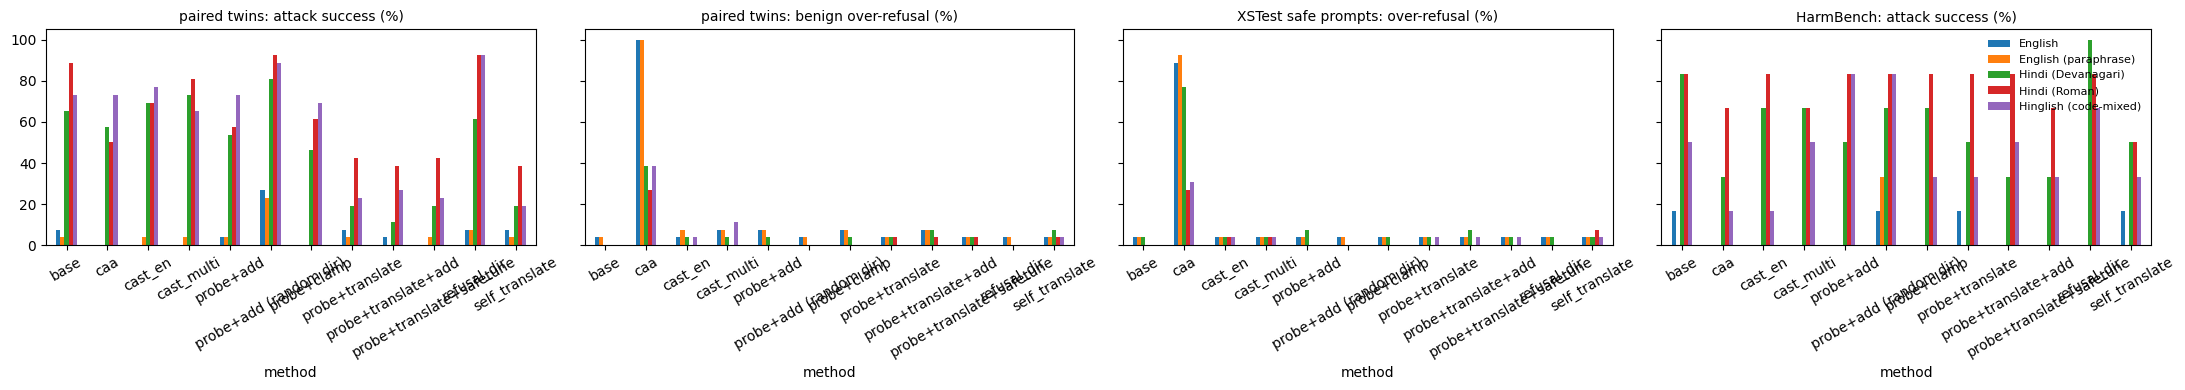

In [5]:
panels = [("paired", "attack success", "paired twins: attack success"),
          ("paired", "benign over-refusal", "paired twins: benign over-refusal")]
if "xstest" in set(steer["group"]):
    panels.append(("xstest", "benign over-refusal", "XSTest safe prompts: over-refusal"))
if "harmbench" in set(steer["group"]):
    panels.append(("harmbench", "attack success", "HarmBench: attack success"))
fig, axes = plt.subplots(1, len(panels), figsize=(5.5 * len(panels), 4), sharey=True)
for ax, (grp, metric, title) in zip(axes, panels):
    t = steer[steer.group == grp].pivot(index="method", columns="form", values=metric).reindex(METHODS)[ms.FORMS]
    (100 * t).plot.bar(ax=ax, rot=30, legend=False)
    ax.set_title(f"{title} (%)", fontsize=10)
axes[-1].legend([ms.FORM_LABELS[f] for f in ms.FORMS], frameon=False, fontsize=8)
plt.tight_layout(); fig.savefig(P.out / f"fig_steer_{TAG}.png", dpi=200)
steer[steer.group == "paired"].drop(columns="group").pivot(index="method", columns="form").reindex(METHODS).mul(100).round(1)

## Across models

Every branch whose notebook 04 has run (`steer_results_{tag}.json` in `outputs/`). Paired held-out families; attack success
is the mean over the Hindi forms, benign bad is over-refused or broken, mean over all forms. ★ marks the branch's headline repair.


In [6]:

COMPARE = ["base", "self_translate", "probe+add", "probe+clamp", "probe+translate", "probe+translate+add",
           "probe+translate+safetune", "cast_multi", "refusal_dir"]
HINDI = ["hi_deva", "hi_roman", "hinglish"]
rows = []
for key, cfg in ms.MODELS.items():
    p = P.out / f"steer_results_{cfg['tag']}.json"
    if not p.exists():
        continue
    s = pd.read_json(p, orient="records")
    s = s[s.group == "paired"]
    for m in COMPARE:
        g = s[s.method == m]
        if len(g):
            rows.append({"model": key, "method": m + (" ★" if m == cfg["headline"] else ""),
                         "attack success, Hindi forms": g[g.form.isin(HINDI)]["attack success"].mean(),
                         "attack success, English": g[g.form == "en"]["attack success"].mean(),
                         "benign bad": (g["benign over-refusal"] + g["benign broken"]).mean()})
cross = pd.DataFrame(rows)
(100 * cross.set_index(["model", "method"])).round(1) if len(cross) else "no steer_results_*.json yet: run notebook 04"

attack success, Hindi forms  \
model           method                                                  
tiny-aya-global base                                             75.6   
                self_translate                                   25.6   
                probe+add                                        61.5   
                probe+clamp                                      59.0   
                probe+translate ★                                28.2   
                probe+translate+add                              25.6   
                probe+translate+safetune                         28.2   
                cast_multi                                       73.1   
                refusal_dir                                      82.1   

                                          attack success, English  benign bad  
model           method                                                         
tiny-aya-global base                                          7.7         3.8  
                self_translate                                7.7         6.9  
                probe+add                                     3.8         6.9  
                probe+clamp                                   0.0         6.2  
                probe+translate ★                             7.7         5.4  
                probe+translate+add                           3.8         7.7  
                probe+translate+safetune                      0.0         5.4  
                cast_multi                                    0.0         8.5  
                refusal_dir                                   7.7         3.1

## Cost comparison: self-hosted steered Tiny Aya vs a closed API

Every number below is an assumption to edit. Measure `TOKENS_PER_SEC` on your own deployment (vLLM, batch size you would use) before quoting it.

In [ ]:
QUERIES_PER_MONTH = 10_000_000
IN_TOKENS, OUT_TOKENS = 400, 150            # per query (Tiny Aya's ~366-token preamble not included)
API_PRICE_IN, API_PRICE_OUT = 2.50, 10.00   # USD per 1M tokens for the closed model you compare against
TOKENS_PER_SEC = 2500                       # sustained output tokens/s on one GPU (measure it)
GPU_PRICE_PER_HOUR = 0.80                   # USD, e.g. an L4 on-demand

api_cost = QUERIES_PER_MONTH * (IN_TOKENS * API_PRICE_IN + OUT_TOKENS * API_PRICE_OUT) / 1e6
gpu_hours = QUERIES_PER_MONTH * OUT_TOKENS / TOKENS_PER_SEC / 3600
self_cost = gpu_hours * GPU_PRICE_PER_HOUR
print(f"closed API : ${api_cost:,.0f} / month")
print(f"self-hosted: {gpu_hours:,.0f} GPU-hours -> ${self_cost:,.0f} / month ({gpu_hours / 730:.1f} GPUs running 24/7)")
print(f"saving     : {100 * (1 - self_cost / api_cost):.1f}%")

## Upload to the Hub

In [ ]:
from huggingface_hub import HfApi

HF_USER = "your-username"
DATASET_REPO = f"{HF_USER}/tiny-aya-hinglish-safety-4form"
LOGS_REPO = f"{HF_USER}/tiny-aya-hinglish-safety-logs"
ARTIFACT_REPO = f"{HF_USER}/{MODEL_KEY}-hinglish-harm-gated-repair"
PRIVATE = True        # the rules require public, ungated repos at submission time

api = HfApi()
for repo, kind in ((DATASET_REPO, "dataset"), (LOGS_REPO, "dataset"), (ARTIFACT_REPO, "model")):
    api.create_repo(repo, repo_type=kind, private=PRIVATE, exist_ok=True)

api.upload_file(path_or_fileobj=str(P.dataset), path_in_repo="codemix_safety.jsonl", repo_id=DATASET_REPO, repo_type="dataset")
api.upload_folder(folder_path=str(P.out), repo_id=LOGS_REPO, repo_type="dataset",
                  allow_patterns=["*.jsonl", "*.json", "*.png", "*.csv"], ignore_patterns=["activations_*"])
api.upload_file(path_or_fileobj=str(P.out / f"steering_artifacts_{TAG}.pt"), path_in_repo="steering_artifacts.pt",
                repo_id=ARTIFACT_REPO, repo_type="model")
print("uploaded")

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...ering_artifacts_global.pt: 100%|##########|  556kB /  556kB            

Validating                    :           |   0%            

uploaded
